# 01 · Quiebres estructurales en la tarifa media (`ruptures`)

> Datos **simulados** con fraude **plantado** sobre líneas y empresas ficticias (`L001`, `E001`). Ver `00c_simulacion_secciones.ipynb`.
> Los resultados sobre datos reales se presentarían como "anomalías a revisar", nunca como prueba de fraude.

## La idea, sin fórmulas
Imaginá la tarifa media de una línea mes a mes como una línea que ondula alrededor de un nivel. Si alguien empieza a cobrar secciones más altas,
el nivel *salta* y se queda ahí: un **quiebre**. Un detector de quiebres busca los momentos en que conviene decir "antes la serie estaba en un nivel y desde acá está en otro".

El problema es que el ruido también produce saltitos. Por eso el algoritmo (**PELT**) cobra una **penalización** por cada quiebre que agrega:
solo acepta uno si mejora el ajuste *más* de lo que cuesta. Penalización alta = más prudente (menos falsas alarmas, pero se escapan casos);
baja = más sensible (detecta más, pero acusa de más).

Dos decisiones de diseño:
1. **Serie relativa:** trabajamos con la tarifa media de cada línea *menos* la mediana de su grupo comparable (Fase 1). Así sacamos lo que le pasa a todas (estacionalidad, shocks comunes) y queda lo propio de la línea.
2. **Solo quiebres hacia arriba:** al fraude le conviene que la tarifa media suba.

In [1]:
import sys; sys.path.append('../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from changepoints import serie_relativa, detectar, calibrar_beta, evaluar
sim = pd.read_parquet('../data/processed/sim_secciones.parquet')
wide = serie_relativa(sim)
# Verdad de referencia (solo para EVALUAR, nunca para detectar): línea con al menos un mes de fraude ACTIVO.
# Ojo: el fraude se asignó a 38 líneas, pero 5 dejaron de reportar antes de 2026, así que su fraude nunca ocurrió en el panel.
verdad = sim.groupby('linea_id').verdad_fraude_activo.any()
print(f"Líneas con fraude asignado: {sim.drop_duplicates('linea_id').verdad_linea_fraude.sum()} | con fraude efectivamente presente en los datos: {verdad.sum()}")
INICIO = '2026-01-01'
wide.shape

Líneas con fraude asignado: 35 | con fraude efectivamente presente en los datos: 27


(82, 390)

## 1. Cómo se ve: una línea con fraude y una sin fraude
Serie relativa (log). La línea punteada marca cuándo se plantó el fraude; el detector **no** conoce esa fecha.

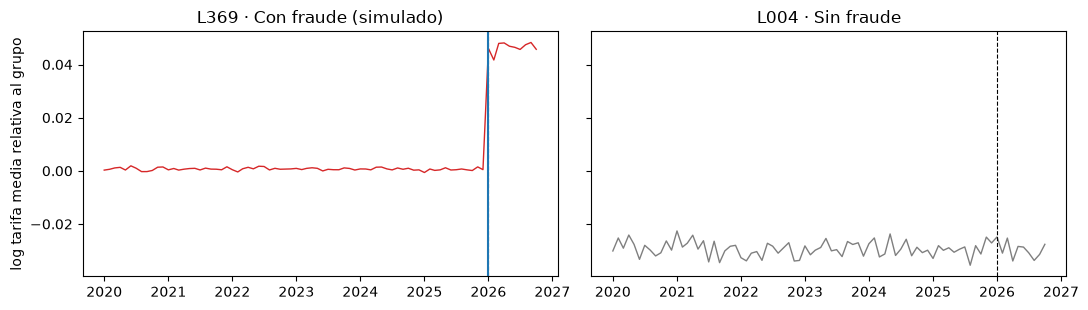

In [2]:
res0 = detectar(wide, beta=4).set_index('linea_id')
con = res0[res0.mes_quiebre.notna() & verdad.reindex(res0.index)].salto_sigma.idxmax()
sin = verdad[~verdad].index[3]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, lid, t in [(axs[0], con, 'Con fraude (simulado)'), (axs[1], sin, 'Sin fraude')]:
    y = wide[lid].dropna(); ax.plot(y.index, y, lw=1, color='tab:red' if verdad[lid] else 'tab:gray')
    ax.axvline(pd.Timestamp(INICIO), ls='--', color='k', lw=.8)
    if pd.notna(res0.loc[lid, 'mes_quiebre']): ax.axvline(res0.loc[lid, 'mes_quiebre'], color='tab:blue', lw=1.5)
    ax.set_title(f'{lid} · {t}')
axs[0].set_ylabel('log tarifa media relativa al grupo'); plt.tight_layout()
plt.savefig('../outputs/figures/m01_ejemplo_quiebre.png', dpi=150); plt.show()

## 2. Elegir la penalización sin hacer trampa
Si ajustáramos el umbral mirando qué líneas tienen fraude, el método quedaría "entrenado con las respuestas". En cambio hacemos un **placebo**:
corremos el detector solo con el período *previo* al fraude (2020-2025), donde todo debería estar quieto, y elegimos la penalización más sensible
que no marque a más del 5 % de las líneas. Supuesto fuerte: que el pasado sea "limpio". En datos reales ese supuesto hay que discutirlo.

In [3]:
beta, tabla = calibrar_beta(wide, hasta=INICIO, tasa_objetivo=0.05)
tabla['tasa_falsas_alarmas'] = (tabla.tasa_falsas_alarmas * 100).round(1)
print(f'Penalización elegida: beta = {beta}')
tabla.rename(columns={'tasa_falsas_alarmas': '% líneas marcadas en el placebo'})

Penalización elegida: beta = 8.0


,beta,% líneas marcadas en el placebo
0,1.0,64.8
1,1.5,35.5
2,2.0,24.0
3,3.0,14.5
4,4.0,9.8
5,5.0,7.7
6,6.0,5.9
7,8.0,3.6
8,10.0,2.1


## 3. Resultado sobre todo el período

In [4]:
res = detectar(wide, beta=beta)
ev = evaluar(res, verdad, INICIO)
cm = pd.DataFrame([[ev['tn'], ev['fp']], [ev['fn'], ev['tp']]], index=['Sin fraude (real)', 'Con fraude (real)'], columns=['No marcada', 'Marcada'])
print(cm.to_string()); print()
print(f"Precisión: {ev['precision']:.0%} (de las marcadas, cuántas tenían fraude)")
print(f"Recall:    {ev['recall']:.0%} (de las que tenían fraude, cuántas se marcaron)")
print(f"Demora mediana: {ev['demora_mediana_meses']:.0f} meses respecto del inicio real")

                   No marcada  Marcada
Sin fraude (real)         316       27
Con fraude (real)           0       26

Precisión: 49% (de las marcadas, cuántas tenían fraude)
Recall:    100% (de las que tenían fraude, cuántas se marcaron)
Demora mediana: 0 meses respecto del inicio real


**Cómo leerlo:** el método ubica bien *cuándo* cambió la serie (el quiebre cae en el mes del inicio) y no se le escapa ninguna línea con fraude presente.
Las falsas alarmas existen porque con 390 líneas y 82 meses el azar produce saltos que parecen reales; eso se controla con la penalización, a costa de perder casos cuando el fraude es más chico.

## 4. Una lección sobre evaluar: las 5 líneas "con fraude" que no aparecían
Si contáramos como fraude a todas las líneas **asignadas** (35), el recall caería a ≈ 74 % (26 de 35). Pero 8 de esas líneas **no tienen ningún dato posterior a enero 2026**: dejaron de reportar antes, así que no hay nada que detectar. Contarlas como fallas sería un error de la *evaluación*, no del método (nos pasó en una primera versión de este análisis). Con la verdad de referencia corregida, el recall es el de arriba.

In [5]:
asignadas = sim.drop_duplicates('linea_id').set_index('linea_id').verdad_linea_fraude
sin_datos = asignadas[asignadas & ~verdad].index
ultimo = sim.groupby('linea_id').mes.max()
print('Líneas con fraude asignado pero sin meses posteriores al inicio; último mes con datos:')
print(ultimo[sin_datos].dt.strftime('%Y-%m').to_dict())
r = res.set_index('linea_id').join(verdad.rename('fraude'))

Líneas con fraude asignado pero sin meses posteriores al inicio; último mes con datos:
{'L296': '2021-06', 'L152': '2025-01', 'L112': '2025-01', 'L033': '2025-01', 'L064': '2025-01', 'L116': '2025-01', 'L013': '2025-11', 'L253': '2025-01'}


## 5. Ranking en vez de "sí/no"
Con datos reales conviene entregar una lista ordenada para revisar. Ordenamos por tamaño del salto en unidades de ruido (σ) y vemos cuántas del top son fraude simulado.

Top 10: 10 con fraude (100%)
Top 25: 23 con fraude (92%)
Top 50: 26 con fraude (52%)


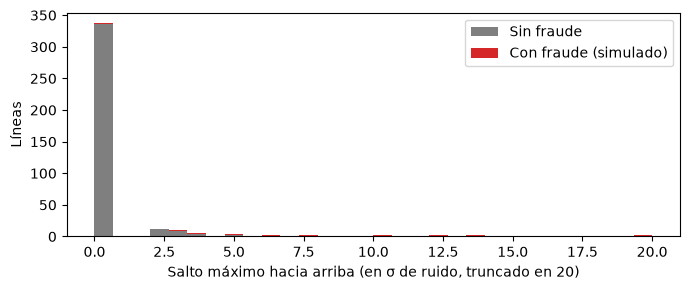

In [6]:
rk = r[r.n_meses >= 12].sort_values('salto_sigma', ascending=False)
for k in (10, 25, 50):
    print(f'Top {k}: {int(rk.head(k).fraude.sum())} con fraude ({rk.head(k).fraude.mean():.0%})')
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist([r[~r.fraude].salto_sigma.clip(upper=20), r[r.fraude].salto_sigma.clip(upper=20)], bins=30, stacked=True, color=['tab:gray', 'tab:red'], label=['Sin fraude', 'Con fraude (simulado)'])
ax.set_xlabel('Salto máximo hacia arriba (en σ de ruido, truncado en 20)'); ax.set_ylabel('Líneas'); ax.legend(); plt.tight_layout()
plt.savefig('../outputs/figures/m01_distribucion_saltos.png', dpi=150); plt.show()

In [7]:
r.reset_index()[['linea_id', 'mes_quiebre', 'salto', 'salto_sigma']].to_parquet('../data/processed/res_m01_changepoints.parquet')

## Limitaciones y qué sigue
- **Sin control externo:** compara cada línea con su pasado y su grupo, pero un quiebre real y legítimo (un cambio de recorrido, una obra) también se marcaría. Un quiebre es una *anomalía a revisar*, no una conclusión.
- **Con fraude del 20 % la señal es fuerte** (el salto es ~10 veces el ruido). Con uno más chico o gradual el recall caería y la demora crecería: la **sensibilidad a la magnitud** se mide en la Fase 4.
- **Pocos meses posteriores:** el quiebre está cerca del final de la serie (10 meses), lo que da poca potencia en casos más sutiles.
- **Siguiente (método 02):** diferencias en diferencias y control sintético, que además estiman el *monto* del perjuicio, algo que el detector de quiebres no hace.